In [1]:
import os
import requests
import re
import collections
import random
import torch
import math

def download_time_machine():
    url = 'http://d2l-data.s3-accelerate.amazonaws.com/timemachine.txt'
    cache_dir = os.path.join('..', 'data')
    os.makedirs(cache_dir, exist_ok=True)
    fname = os.path.join(cache_dir, 'timemachine.txt')
    
    if not os.path.exists(fname):
        print("正在下载 timemachine.txt ...")
        r = requests.get(url)
        r.raise_for_status()
        with open(fname, 'wb') as f:
            f.write(r.content)
        print("下载完成！")
        
    with open(fname, 'r', encoding='utf-8') as f:
        lines = f.readlines()
        
    ## 转小写，只保留字母和空格，去除标点和换行符
    return [re.sub('[^A-Za-z]+', ' ', line).strip().lower() for line in lines]

lines = download_time_machine()
print("文本行数:", len(lines))


class Vocab:
    def __init__(self, tokens=None, min_freq=0, reserved_tokens=None):
        if tokens is None:
            tokens = []
        if reserved_tokens is None:
            reserved_tokens = []
            
        # 统计词频
        counter = collections.Counter(tokens)
        self._token_freqs = sorted(counter.items(), key=lambda x: x[1], reverse=True)
        
        # 建立索引到词元的映射
        self.idx_to_token = ['<unk>'] + reserved_tokens
        self.token_to_idx = {token: idx for idx, token in enumerate(self.idx_to_token)}
        
        for token, freq in self._token_freqs:
            if freq < min_freq:
                break
            if token not in self.token_to_idx:
                self.idx_to_token.append(token)
                self.token_to_idx[token] = len(self.idx_to_token) - 1

    def __len__(self):
        return len(self.idx_to_token)

    def __getitem__(self, tokens):
        if not isinstance(tokens, (list, tuple)):
            return self.token_to_idx.get(tokens, self.unk)
        return [self.__getitem__(token) for token in tokens]

    def to_tokens(self, indices):
        if not isinstance(indices, (list, tuple)):
            return self.idx_to_token[indices]
        return [self.idx_to_token[index] for index in indices]

    @property
    def unk(self):
        return 0  # <unk> 的索引为 0

# 将文本按字符拆分为列表
corpus_chars = [char for line in lines for char in line]
vocab = Vocab(corpus_chars, min_freq=1, reserved_tokens=['<pad>'])
print("词汇表大小:", len(vocab))

# 将整个文本转化为索引列表
corpus = [vocab[char] for char in corpus_chars]
print("语料库长度:", len(corpus))


# ==========================================
# 3. 数据采样生成器
# ==========================================
def seq_data_iter_sequential(corpus, batch_size, num_steps):
    """顺序分区采样"""
    offset = random.randint(0, num_steps)
    num_tokens = ((len(corpus) - offset - 1) // batch_size) * batch_size
    Xs = torch.tensor(corpus[offset: offset + num_tokens])
    Ys = torch.tensor(corpus[offset + 1: offset + 1 + num_tokens])
    Xs = Xs.reshape(batch_size, -1)
    Ys = Ys.reshape(batch_size, -1)
    num_batches = Xs.shape[1] // num_steps
    for i in range(0, num_steps * num_batches, num_steps):
        X = Xs[:, i: i + num_steps]
        Y = Ys[:, i: i + num_steps]
        yield X, Y

def seq_data_iter_random(corpus, batch_size, num_steps):
    """随机采样"""
    corpus = corpus[random.randint(0, num_steps - 1):]
    num_subseqs = (len(corpus) - 1) // num_steps
    initial_indices = list(range(0, num_subseqs * num_steps, num_steps))
    random.shuffle(initial_indices)
    
    def data(pos):
        return corpus[pos: pos + num_steps]
        
    num_batches = num_subseqs // batch_size
    for i in range(0, batch_size * num_batches, batch_size):
        initial_indices_per_batch = initial_indices[i: i + batch_size]
        X = [data(j) for j in initial_indices_per_batch]
        Y = [data(j + 1) for j in initial_indices_per_batch]
        yield torch.tensor(X), torch.tensor(Y)


# ==========================================
# 4. 包装成可重复迭代的 DataLoader
# ==========================================
class SeqDataLoader:
    """可重复迭代的序列数据加载器（避免生成器被耗尽导致除零错误）"""
    def __init__(self, corpus, batch_size, num_steps, use_random_iter=False):
        self.corpus = corpus
        self.batch_size = batch_size
        self.num_steps = num_steps
        self.use_random_iter = use_random_iter

    def __iter__(self):
        if self.use_random_iter:
            return seq_data_iter_random(self.corpus, self.batch_size, self.num_steps)
        else:
            return seq_data_iter_sequential(self.corpus, self.batch_size, self.num_steps)


# ==========================================
# 5. 生成最终你需要的 train_iter 和 vocab
# ==========================================
batch_size, num_steps = 32, 35
# 默认使用顺序分区（use_random_iter=False）
train_iter = SeqDataLoader(corpus, batch_size, num_steps, use_random_iter=False)

# 测试迭代器是否正常工作（输出两个相同的数字说明可以重复迭代）
print("第一次迭代批次数:", sum(1 for _ in train_iter))
print("第二次迭代批次数:", sum(1 for _ in train_iter))

文本行数: 3221
词汇表大小: 29
语料库长度: 170580
第一次迭代批次数: 152
第二次迭代批次数: 152


In [3]:
import torch 
from torch import nn
from d2l import  torch as d2l

In [7]:
def get_lstm_params(vocab_size,num_hiddens,device):
    num_inputs = num_outputs = vocab_size
    def normal(shape):
        return torch.randn(
            size = shape,
            device = device
        )*0.01
    def three():
        return (
            normal((num_inputs,num_hiddens)),
            normal((num_hiddens,num_hiddens)),
            torch.zeros(num_hiddens,device=device)
        )
    W_xi,W_hi,b_i = three()
    W_xf,W_hf,b_f = three()
    W_xo,W_ho,b_o = three()
    W_xc,W_hc,b_c = three()
    W_hq = normal((num_hiddens,num_outputs))
    b_q = torch.zeros(num_outputs,device=device)

    params = [W_xi,W_hi,b_i,W_xf,W_hf,b_f,W_xo,W_ho,b_o,W_xc,W_hc,b_c,W_hq,b_q]

    for para in params:
        para.requires_grad_(True)
    return params

In [8]:
def init_lstm_state(batch_size,num_hiddens,device):
    return (torch.zeros((batch_size,num_hiddens),device=device),
            torch.zeros((batch_size,num_hiddens),device=device))
            

In [10]:
def lstm(inputs,state,params):
    [W_xi, W_hi, b_i, W_xf, W_hf, b_f, W_xo, W_ho, b_o, W_xc, W_hc, b_c,W_hq, b_q] = params
    (H,C) = state
    outputs = []

    for X in inputs:
        I = torch.sigmoid(
            (X@W_xi) + (H@W_hi) + b_i
        )
        F = torch.sigmoid(
            (X@W_xf) + (H@W_hf) + b_f
        )
        O = torch.sigmoid(
            (X@W_xo) + (H@W_ho) + b_o
        )
        C_tilda = torch.tanh(
            (X@W_xc) + (H@W_hc) + b_c
        )
        C = F*C + I*C_tilda
        H = O*torch.tanh(C)
        Y = (H@W_hq) + b_q
        outputs.append(Y)
    return torch.cat(outputs,dim=0),(H,C)


In [11]:
import math
import random
import time
import os
import re
import collections
import requests
import matplotlib.pyplot as plt
from IPython import display
import torch
import torch.nn as nn
import torch.nn.functional as F

# 设备选择：优先 CUDA > MPS > CPU
if torch.cuda.is_available():
    device = torch.device('cuda')
elif torch.backends.mps.is_available():
    device = torch.device('mps')
else:
    device = torch.device('cpu')

print("使用设备:", device)

使用设备: mps


In [12]:
class Timer:
    def __init__(self):
        self.times = []
        self.start()
    def start(self):
        self.tik = time.time()
    def stop(self):
        self.times.append(time.time() - self.tik)
        return self.times[-1]


class Accumulator:
    def __init__(self, n):
        self.data = [0.0] * n
    def add(self, *args):
        self.data = [a + float(b) for a, b in zip(self.data, args)]
    def __getitem__(self, idx):
        return self.data[idx]


class Animator:
    def __init__(self, xlabel=None, ylabel=None, legend=None,
                 xlim=None, ylim=None, fmts=('-', 'm--', 'g-.', 'r:'),
                 figsize=(4.5, 3.5)):
        if legend is None:
            legend = []
        self.fig, self.ax = plt.subplots(figsize=figsize)
        self.legend = legend
        self.X, self.Y, self.fmts = None, None, fmts
        self.xlabel, self.ylabel = xlabel, ylabel
        if xlim:
            self.ax.set_xlim(xlim)
        if ylim:
            self.ax.set_ylim(ylim)
        self.ax.set_xlabel(xlabel)
        self.ax.set_ylabel(ylabel)
        self.ax.grid(True)

    def add(self, x, y):
        if not hasattr(y, "__len__"):
            y = [y]
        n = len(y)
        if not hasattr(x, "__len__"):
            x = [x] * n
        if self.X is None:
            self.X = [[] for _ in range(n)]
            self.Y = [[] for _ in range(n)]
        for i, (a, b) in enumerate(zip(x, y)):
            self.X[i].append(a)
            self.Y[i].append(b)
        self.ax.cla()
        self.ax.set_xlabel(self.xlabel)
        self.ax.set_ylabel(self.ylabel)
        self.ax.grid(True)
        if self.legend:
            self.ax.legend(self.legend)
        for i in range(n):
            self.ax.plot(self.X[i], self.Y[i], self.fmts[i % len(self.fmts)])
        display.display(self.fig)
        display.clear_output(wait=True)

In [13]:
class RNNModelScratch:
    """从零实现的循环神经网络模型"""
    def __init__(self, vocab_size, num_hiddens, device,
                 get_params, init_state, forward_fn):
        self.vocab_size, self.num_hiddens = vocab_size, num_hiddens
        self.params = get_params(vocab_size, num_hiddens, device)
        self.init_state, self.forward_fn = init_state, forward_fn

    def __call__(self, X, state):
        X = F.one_hot(X.T, self.vocab_size).type(torch.float32)
        return self.forward_fn(X, state, self.params)

    def begin_state(self, batch_size, device):
        return self.init_state(batch_size, self.num_hiddens, device)

In [14]:
def sgd(params, lr, batch_size):
    with torch.no_grad():
        for param in params:
            param -= lr * param.grad / batch_size
            param.grad.zero_()

In [15]:
def predict_ch8(prefix, num_preds, net, vocab, device):
    state = net.begin_state(batch_size=1, device=device)
    outputs = [vocab[prefix[0]]]
    def get_input():
        return torch.tensor([outputs[-1]], device=device).reshape((1, 1))
    for y in prefix[1:]:
        _, state = net(get_input(), state)
        outputs.append(vocab[y])
    for _ in range(num_preds):
        y, state = net(get_input(), state)
        outputs.append(int(y.argmax(dim=1).reshape(1)))
    return ''.join([vocab.idx_to_token[i] for i in outputs])

In [16]:
def grad_clipping(net, theta):
    if isinstance(net, nn.Module):
        params = [p for p in net.parameters() if p.requires_grad]
    else:
        params = net.params
    grads = [p.grad for p in params if p.grad is not None]
    if len(grads) == 0:
        return
    norm = torch.sqrt(sum(torch.sum(g ** 2) for g in grads))
    if norm > theta:
        for param in params:
            if param.grad is not None:
                param.grad[:] *= theta / norm

In [17]:
def train_epoch_ch8(net, train_iter, loss, updater, device, use_random_iter):
    state, timer = None, Timer()
    metric = Accumulator(2)
    for X, Y in train_iter:
        if state is None or use_random_iter:
            state = net.begin_state(batch_size=X.shape[0], device=device)
        else:
            if isinstance(net, nn.Module) and not isinstance(state, tuple):
                state.detach_()
            else:
                for s in state:
                    s.detach_()
        y = Y.T.reshape(-1)
        X, y = X.to(device), y.to(device)
        y_hat, state = net(X, state)
        l = loss(y_hat, y.long()).mean()
        if isinstance(updater, torch.optim.Optimizer):
            updater.zero_grad()
            l.backward()
            grad_clipping(net, 1)
            updater.step()
        else:
            l.backward()
            grad_clipping(net, 1)
            updater(batch_size=1)
        metric.add(l * y.numel(), y.numel())
    return math.exp(metric[0] / metric[1]), metric[1] / timer.stop()

In [18]:
def train_ch8(net, train_iter, vocab, lr, num_epochs, device,
              use_random_iter=False):
    loss = nn.CrossEntropyLoss()
    animator = Animator(xlabel='epoch', ylabel='perplexity',
                        legend=['train'], xlim=[10, num_epochs])

    if isinstance(net, nn.Module):
        updater = torch.optim.SGD(net.parameters(), lr)
    else:
        def updater(batch_size):
            return sgd(net.params, lr, batch_size)

    def predict(prefix):
        return predict_ch8(prefix, 50, net, vocab, device)

    for epoch in range(num_epochs):
        ppl, speed = train_epoch_ch8(
            net, train_iter, loss, updater, device, use_random_iter)
        if (epoch + 1) % 10 == 0:
            print(predict('time traveller'))
        animator.add(epoch + 1, [ppl])

    print(f'困惑度 {ppl:.1f}, {speed:.1f} 词元/秒 {str(device)}')
    print(predict('time traveller'))
    print(predict('traveller'))

困惑度 1.3, 52886.7 词元/秒 mps
time traveller asist and theni could smoked my first was look it
traveller from the hour wroced had as for a momentit me to 


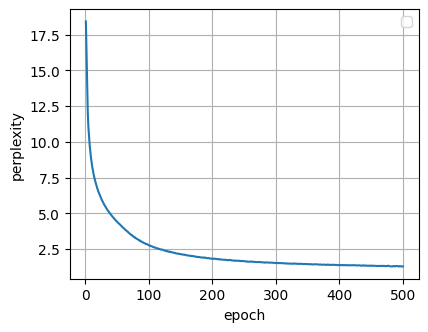

In [19]:
vocab_size, num_hiddens = len(vocab), 256
num_epochs, lr = 500, 1

model = RNNModelScratch(
    len(vocab), num_hiddens, device,
    get_lstm_params,
    init_lstm_state,
    lstm
)

train_ch8(model, train_iter, vocab, lr, num_epochs, device)